# PS4: LSTM for character-level text generation
Corpus: Shakespeare text, downloaded automatically.

In [2]:

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

if not gpus:
    print("=" * 62)
    print("GPU NOT FOUND - Running LSTM on CPU instead.")
    print("=" * 62)
    device_name = "CPU"
else:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

    print("Using GPU:", gpus[0].name)
    device_name = gpus[0].name

print("Selected device:", device_name)


GPU NOT FOUND - Running LSTM on CPU instead.
Selected device: CPU


In [3]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

EPOCHS = 15
SEQ_LEN = 40
MAX_CHARS = 200000
keras.utils.set_random_seed(42)

In [4]:
path = keras.utils.get_file(
    "shakespeare.txt",
    "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt",
)
text = open(path, encoding="utf-8").read().lower()[:MAX_CHARS]
chars = sorted(set(text))
char_to_id = {c: i for i, c in enumerate(chars)}
id_to_char = np.array(chars)
print("Characters:", len(text), "Vocabulary:", len(chars))
print(text[:300])

Characters: 200000 Vocabulary: 37
first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us


In [5]:
encoded = np.array([char_to_id[c] for c in text])
starts = range(0, len(encoded) - SEQ_LEN, 3)
X = np.array([encoded[i:i + SEQ_LEN] for i in starts])
y = np.array([encoded[i + SEQ_LEN] for i in starts])
print("X:", X.shape, "y:", y.shape)

X: (66654, 40) y: (66654,)


In [6]:
model = keras.Sequential([
    layers.Input((None,)),
    layers.Embedding(len(chars), 64),
    layers.LSTM(256),
    layers.Dense(len(chars), activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, None, 64)            │           2,368 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 256)                 │         328,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 37)                  │           9,509 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 340,581 (1.30 MB)

 Trainable params: 340,581 (1.30 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(X, y, epochs=EPOCHS, batch_size=128, validation_split=0.1, verbose=2)

Epoch 1/15
469/469 - 56s - 120ms/step - accuracy: 0.2737 - loss: 2.5635 - val_accuracy: 0.3404 - val_loss: 2.2627
Epoch 2/15
469/469 - 57s - 122ms/step - accuracy: 0.3899 - loss: 2.0741 - val_accuracy: 0.3983 - val_loss: 2.0616
Epoch 3/15
469/469 - 57s - 122ms/step - accuracy: 0.4433 - loss: 1.8760 - val_accuracy: 0.4266 - val_loss: 1.9504
Epoch 4/15
469/469 - 58s - 124ms/step - accuracy: 0.4812 - loss: 1.7334 - val_accuracy: 0.4505 - val_loss: 1.8716
Epoch 5/15
469/469 - 59s - 126ms/step - accuracy: 0.5104 - loss: 1.6228 - val_accuracy: 0.4652 - val_loss: 1.8286
Epoch 6/15
469/469 - 58s - 125ms/step - accuracy: 0.5329 - loss: 1.5354 - val_accuracy: 0.4716 - val_loss: 1.8123
Epoch 7/15
469/469 - 59s - 126ms/step - accuracy: 0.5555 - loss: 1.4575 - val_accuracy: 0.4767 - val_loss: 1.8108
Epoch 8/15
469/469 - 59s - 125ms/step - accuracy: 0.5753 - loss: 1.3830 - val_accuracy: 0.4796 - val_loss: 1.8195
Epoch 9/15
469/469 - 59s - 126ms/step - accuracy: 0.5976 - loss: 1.3093 - val_accuracy: 

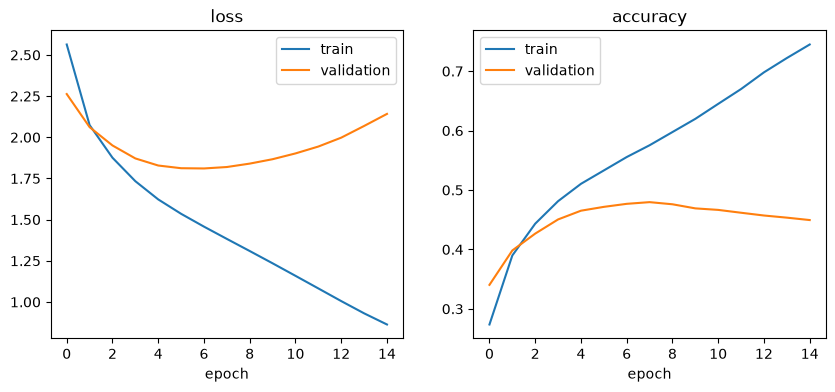

Final validation accuracy: 0.4494
Validation perplexity: 8.52


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[metric], label="train")
    ax[i].plot(history.history["val_" + metric], label="validation")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Validation perplexity: {np.exp(history.history['val_loss'][-1]):.2f}")

In [ ]:
def generate(seed, n_chars=400, temperature=1.0):
    sentence = seed.lower()
    for _ in range(n_chars):
        context = sentence[-SEQ_LEN:]
        x = np.array([[char_to_id[c] for c in context]])
        probs = model.predict(x, verbose=0)[0]
        logits = np.log(probs + 1e-8) / temperature
        probs = np.exp(logits) / np.exp(logits).sum()
        sentence += id_to_char[np.random.choice(len(chars), p=probs)]
    return sentence

seed = "second citizen:\n"
for t in [0.2, 0.5, 1.0]:
    print(f"--- temperature {t} ---")
    print(generate(seed, temperature=t))
    print()

--- temperature 0.2 ---
